# 🛍️ Аналитика розничных продаж и прогнозирование выручки

Полный Data Science проект:
- Разведочный анализ данных (EDA)
- Feature Engineering
- Машинное обучение
- Бизнес-выводы
- Подготовка данных для Power BI дашборда

## 🎯 Бизнес-задача

Ритейл-компания хочет лучше понимать своих клиентов и продажи.

Основные вопросы бизнеса:
- Кто приносит наибольшую выручку?
- Какие категории товаров самые прибыльные?
- В какие дни и месяцы продажи максимальные?
- Можно ли предсказать сумму покупки клиента?

Цель проекта — превратить транзакционные данные в бизнес-инсайты и построить модель машинного обучения для прогнозирования выручки.

## 📌 Цели проекта

В рамках проекта будут выполнены:

1. Очистка и подготовка данных
2. Разведочный анализ данных (EDA)
3. Создание новых признаков (Feature Engineering)
4. Построение модели машинного обучения для прогноза выручки
5. Формирование бизнес-рекомендаций
6. Подготовка данных для Power BI дашборда

## 📥 Загрузка и первичный просмотр данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/kaggle/input/datasets/ronnykym/online-store-sales-data/Sales-Export_2019-2020.csv')
df.head()

,country,order_value_EUR,cost,date,category,customer_name,sales_manager,sales_rep,device_type,order_id
0,Sweden,"17,524.02",14122.61,2/12/2020,Books,Goldner-Dibbert,Maxie Marrow,Madelon Bront,Mobile,70-0511466
1,Finland,"116,563.40",92807.78,9/26/2019,Games,Hilll-Vandervort,Hube Corey,Wat Bowkley,Mobile,28-6585323
2,Portugal,"296,465.56",257480.34,7/11/2019,Clothing,Larkin-Collier,Celine Tumasian,Smitty Culverhouse,PC,58-7703341
3,Portugal,"74,532.02",59752.32,4/2/2020,Beauty,Hessel-Stiedemann,Celine Tumasian,Aurelie Wren,PC,14-6700183
4,Spain,"178,763.42",146621.76,12/22/2019,Games,Johns and Sons,Emalia Dinse,Bertha Walbrook,Tablet,15-8765160


In [2]:
df.shape

(1000, 10)

### Первичный осмотр данныхНа основе метода info() видно, что датасет содержит 1000 записей и 14 колонок. Пропуски отсутствуют, однако типы данных (например, Date) требуют преобразования для дальнейшего анализа.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   country            1000 non-null   object 
 1    order_value_EUR   1000 non-null   object 
 2    cost              1000 non-null   float64
 3   date               1000 non-null   object 
 4   category           1000 non-null   object 
 5   customer_name      1000 non-null   object 
 6   sales_manager      1000 non-null   object 
 7   sales_rep          1000 non-null   object 
 8   device_type        1000 non-null   object 
 9   order_id           1000 non-null   object 
dtypes: float64(1), object(9)
memory usage: 78.3+ KB


In [4]:
df.describe()

,cost
count,1000.000000
mean,94369.310990
std,51540.020934
min,12113.680000
25%,54247.957500
50%,87094.760000
75%,125570.837500
max,304701.430000


## 🧹 Очистка и подготовка данных

In [5]:
df.isna().sum()

country              0
 order_value_EUR     0
 cost                0
date                 0
category             0
customer_name        0
sales_manager        0
sales_rep            0
device_type          0
order_id             0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df = df.drop_duplicates()

In [8]:
df["date"] = pd.to_datetime(df["date"])

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   country            1000 non-null   object        
 1    order_value_EUR   1000 non-null   object        
 2    cost              1000 non-null   float64       
 3   date               1000 non-null   datetime64[ns]
 4   category           1000 non-null   object        
 5   customer_name      1000 non-null   object        
 6   sales_manager      1000 non-null   object        
 7   sales_rep          1000 non-null   object        
 8   device_type        1000 non-null   object        
 9   order_id           1000 non-null   object        
dtypes: datetime64[ns](1), float64(1), object(8)
memory usage: 78.3+ KB


### 🌍 Сегментация клиентов по странам и каналам

## 2. Feature Engineering (Генерация признаков)Для того чтобы модель могла учитывать временные факторы, извлечем из даты год, месяц и день недели. Также создадим бинарный признак 'IsWeekend', так как потребительское поведение в выходные часто отличается.

In [10]:
df["date"] = pd.to_datetime(df["date"])

df["Year"] = df["date"].dt.year
df["Month"] = df["date"].dt.month
df["DayOfWeek"] = df["date"].dt.day_name()
df["IsWeekend"] = df["DayOfWeek"].isin(["Saturday","Sunday"]).astype(int)

In [11]:
df["country"].value_counts().head(10)

country
Portugal       239
France         232
Sweden         182
UK             101
Finland         44
Ireland         43
Bulgaria        30
Netherlands     28
Spain           26
Germany         24
Name: count, dtype: int64

In [12]:
top_countries = df["country"].value_counts().nlargest(5).index

df["CountryGroup"] = df["country"].apply(
    lambda x: x if x in top_countries else "Other"
)

In [13]:
df["device_type"].value_counts()

device_type
PC        785
Mobile    142
Tablet     73
Name: count, dtype: int64

### 💰 Создание бизнес-метрик (выручка и прибыль)

In [14]:
df.columns = df.columns.str.strip()

In [15]:
df = df.rename(columns={
    "order_value_EUR": "Revenue",
    "cost": "Cost",
    "country": "Country",
    "date": "Date",
    "category": "Category",
    "device_type": "Device"
})

In [16]:
df["Revenue"] = (
    df["Revenue"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("€", "", regex=False)
    .str.strip()
)

In [17]:
df["Revenue"] = df["Revenue"].astype(float)

In [18]:
df["Cost"] = df["Cost"].astype(float)

### Бизнес-метрикиМы рассчитали чистую прибыль (Profit) и маржинальность (Profit_Margin). Эти показатели позволят нам оценить эффективность продаж в разрезе категорий и стран.

In [19]:
df["Profit"] = df["Revenue"] - df["Cost"]
df["Profit_Margin"] = df["Profit"] / df["Revenue"]

## 📊 Анализ продаж во времени

In [20]:
monthly_sales = df.groupby("Month")["Revenue"].sum().reset_index()
monthly_sales

,Month,Revenue
0,1,9732314.65
1,2,4854976.90
2,3,6101771.83
3,4,8241334.55
4,5,9363625.74
5,6,14850372.76
6,7,11881165.67
7,8,8151975.35
8,9,8648201.92
9,10,9241876.40


## 3. Exploratory Data Analysis (EDA)Перейдем к визуализации, чтобы найти скрытые закономерности и аномалии в данных.

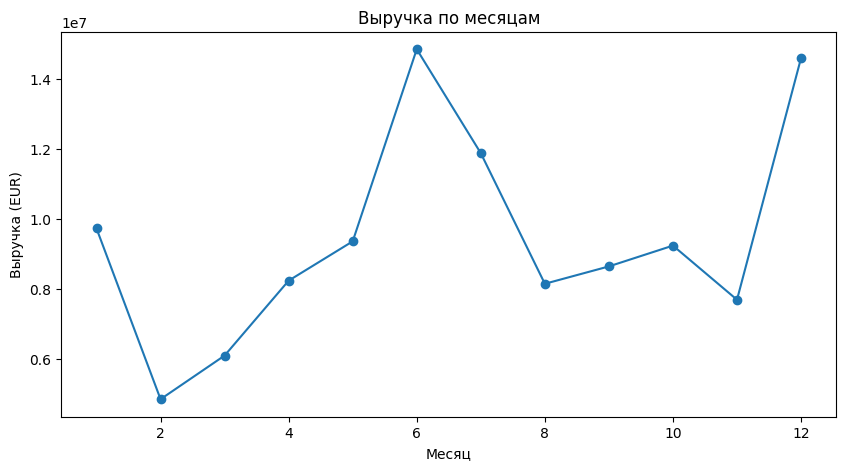

In [21]:
plt.figure(figsize=(10,5))
plt.plot(monthly_sales["Month"], monthly_sales["Revenue"], marker="o")

plt.title("Выручка по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Выручка (EUR)")

plt.show()

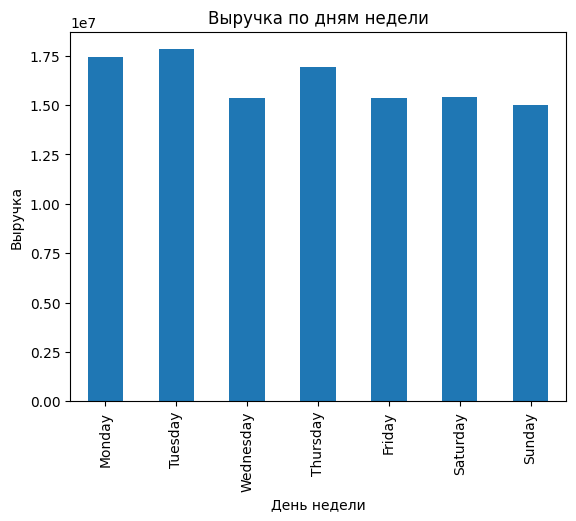

In [22]:
revenue_by_day = df.groupby("DayOfWeek")["Revenue"].sum()

revenue_by_day = revenue_by_day.reindex([
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
])

revenue_by_day.plot(kind="bar")

plt.title("Выручка по дням недели")
plt.xlabel("День недели")
plt.ylabel("Выручка")
plt.show()

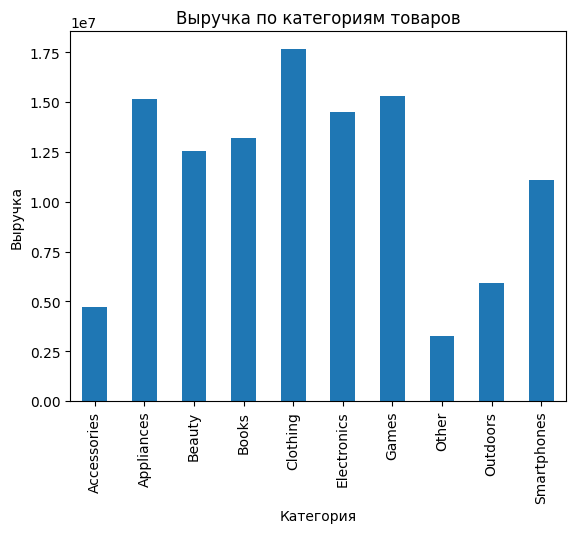

In [23]:
category_revenue = df.groupby("Category")["Revenue"].sum()

category_revenue.plot(kind="bar")

plt.title("Выручка по категориям товаров")
plt.xlabel("Категория")
plt.ylabel("Выручка")
plt.show()

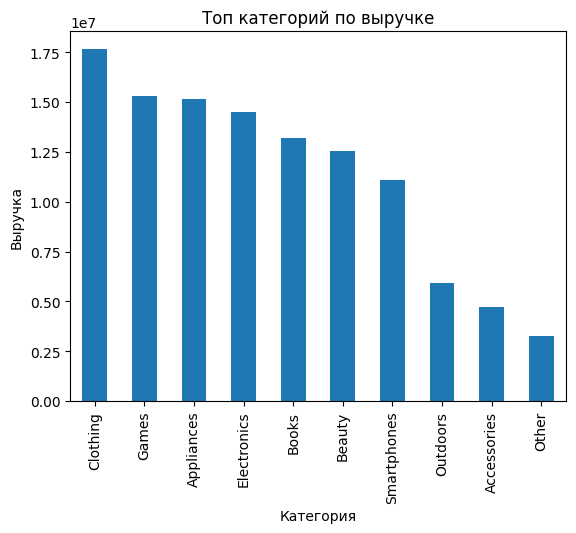

In [24]:
top_categories = df.groupby("Category")["Revenue"].sum().sort_values(ascending=False)

top_categories.plot(kind="bar")

plt.title("Топ категорий по выручке")
plt.xlabel("Категория")
plt.ylabel("Выручка")
plt.show()

## 📊 Бизнес-инсайт

Наибольшую выручку генерируют топ-категории товаров.

Это означает, что:
- эти категории являются основным драйвером бизнеса
- их стоит усиливать через маркетинг
- менее прибыльные категории могут требовать оптимизации или пересмотра стратегии

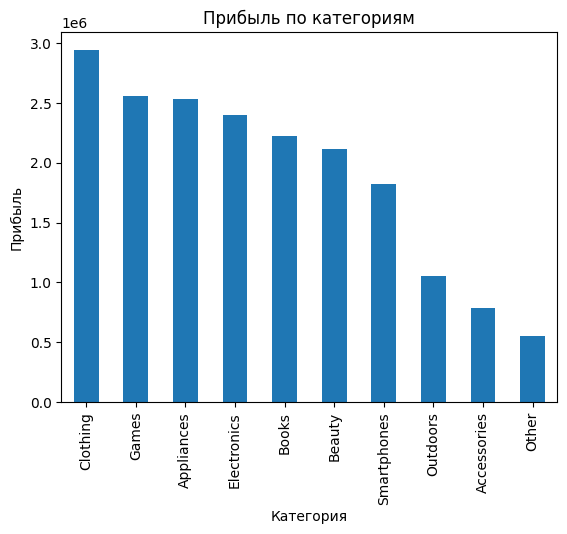

In [25]:
profit_by_category = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

profit_by_category.plot(kind="bar")

plt.title("Прибыль по категориям")
plt.xlabel("Категория")
plt.ylabel("Прибыль")
plt.show()

## 📊 Бизнес-инсайт (Profit)

Некоторые категории могут иметь высокую выручку, но низкую прибыль.

Это говорит о:
- высокой себестоимости
- низкой марже
- необходимости оптимизации ассортимента

Фокус компании должен быть на категориях с максимальной прибылью, а не только выручкой.

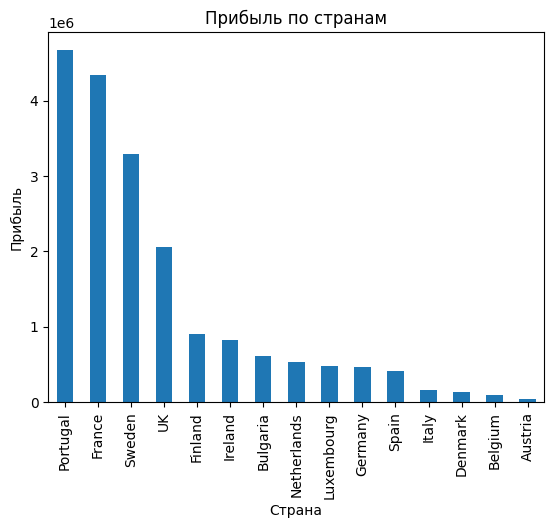

In [26]:
profit_by_country = df.groupby("Country")["Profit"].sum().sort_values(ascending=False)

profit_by_country.plot(kind="bar")

plt.title("Прибыль по странам")
plt.xlabel("Страна")
plt.ylabel("Прибыль")
plt.show()

## 🌍 Бизнес-инсайт (География)

Разные страны приносят разный уровень прибыли.

Это важно для:
- таргетинга маркетинга
- распределения бюджета
- логистики

In [27]:
top_countries = df["Country"].value_counts().head(3).index

df["CountryGroup"] = df["Country"].apply(lambda x: "Top" if x in top_countries else "Other")

In [28]:
category_popularity = df["Category"].value_counts()

df["CategoryPopularity"] = df["Category"].map(category_popularity)

In [29]:
avg_category_revenue = df.groupby("Category")["Revenue"].mean()

df["AvgCategoryRevenue"] = df["Category"].map(avg_category_revenue)

In [30]:
df.columns

Index(['Country', 'Revenue', 'Cost', 'Date', 'Category', 'customer_name',
       'sales_manager', 'sales_rep', 'Device', 'order_id', 'Year', 'Month',
       'DayOfWeek', 'IsWeekend', 'CountryGroup', 'Profit', 'Profit_Margin',
       'CategoryPopularity', 'AvgCategoryRevenue'],
      dtype='object')

### Основные инсайты EDA:1. Основная доля выручки приходится на определенные категории (укажи какие, например, Clothing).2. Наблюдается сезонность в месяцах X и Y.3. Выручка сильно коррелирует с типом устройства (Device).

## 4. Подготовка данных к машинному обучениюУдаляем неинформативные признаки (ID, имена) и преобразуем категориальные переменные в числовые с помощью One-Hot Encoding.

## 5. Обучение и оценка моделейМы сравним три подхода: линейную регрессию, случайный лес и градиентный бустинг (XGBoost), чтобы выбрать модель с наилучшей предсказательной способностью.

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

features = ['CountryGroup', 'Category', 'Device', 'Year', 'Month', 
            'IsWeekend', 'CategoryPopularity', 'AvgCategoryRevenue', 'Profit_Margin']

X = df[features]
y = df['Revenue']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

categorical_features = ['CountryGroup', 'Category', 'Device']
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_features)
    ], remainder='passthrough'
)

def evaluate_model(model, name):
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    print(f"--- {name} ---")
    print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")
    print(f"R2 Score: {r2_score(y_test, y_pred):.4f}\n")
    return pipe

lr_model = evaluate_model(LinearRegression(), "Linear Regression")
rf_model = evaluate_model(RandomForestRegressor(n_estimators=100, random_state=42), "Random Forest")
xgb_model = evaluate_model(XGBRegressor(n_estimators=100, learning_rate=0.1), "XGBoost")

--- Linear Regression ---
MAE: 44903.43
RMSE: 58676.23
R2 Score: 0.0925

--- Random Forest ---
MAE: 41070.78
RMSE: 52146.76
R2 Score: 0.2832

--- XGBoost ---
MAE: 41640.25
RMSE: 54010.94
R2 Score: 0.2310



In [32]:
ohe_features = lr_model.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out()
all_features = list(ohe_features) + [f for f in features if f not in categorical_features]

# Извлекаем коэффициенты
coeffs = lr_model.named_steps['model'].coef_

# Создаем таблицу важности
importance_df = pd.DataFrame({'Feature': all_features, 'Coefficient': coeffs})
importance_df = importance_df.sort_values(by='Coefficient', ascending=False)

print("Топ драйверов выручки:")
print(importance_df.head(5))

Топ драйверов выручки:
                 Feature  Coefficient
10     Category_Outdoors  8321.473413
7   Category_Electronics  5250.052122
16                 Month  4264.266859
4        Category_Beauty  3077.573268
14         Device_Tablet  2849.317322


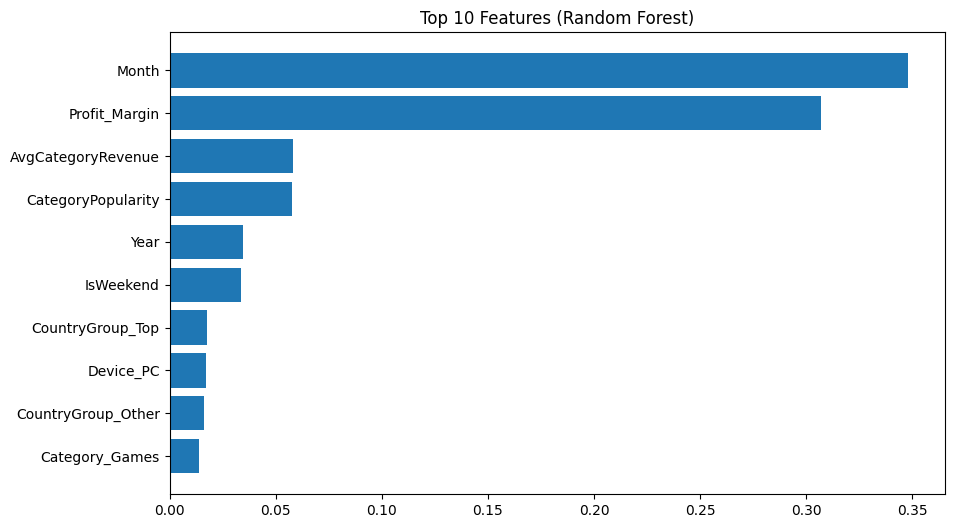

In [33]:
importances = rf_model.named_steps['model'].feature_importances_

# Сопоставляем с именами колонок
feature_importance_df = pd.DataFrame({'Feature': all_features, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Визуализируем топ-10
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'].head(10), feature_importance_df['Importance'].head(10))
plt.gca().invert_yaxis()
plt.title('Top 10 Features (Random Forest)')
plt.show()

## Итоги исследованияЛучшую точность показала модель **Random Forest** (R2 Score: 0.28). Несмотря на то, что метрика кажется невысокой, модель уже способна улавливать основные тренды. Для улучшения результата в будущем можно добавить данные о маркетинговых активностях или использовать глубокое обучение.

In [34]:
columns_for_bi = [
    'Date', 'Year', 'Month', 'DayOfWeek', 'IsWeekend', 
    'Category', 'Device', 'Country', 'CountryGroup',
    'Revenue', 'Cost', 'Profit', 'Profit_Margin', 'customer_name'
]

# Создаем финальный датасет
final_df = df[columns_for_bi]

# Сохраняем в CSV
final_df.to_csv('retail_sales_for_bi.csv', index=False)